# Mechanistic-conditioning comparison on the experimental test set

This notebook addresses the Supplementary Figure 15 reviewer question by comparing the same inverse-decoding task for three training sources:

1. **Raw simulations** (the previously saved raw-simulation decoder outputs)
2. **Seed-conditioned ControlNet generation** (legacy decoder for the preliminary analysis)
3. **Simulation-conditioned ControlNet generation** (N=30,000, `last.ckpt`)

All methods are scored against the same audited experimental test targets (96 random-condition + 36 fixed-condition images; 132 total). The primary metric is per-image Hungarian point-matching F1 at the established 4-pixel tolerance. The main plot shows the mean with standard-deviation error bars.

> Uses the completed corrected seed-conditioned model with native 32×32 targets and a configuration-grouped split.


In [1]:
import gc
import hashlib
import json
import os
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from torch.utils.data import DataLoader

# Support launching from this directory or from the repository root.
if not Path('inverse_evaluation.py').is_file():
    candidate = Path.cwd() / 'information_encoding_decoding'
    if candidate.is_dir():
        os.chdir(candidate)

import inverse_evaluation as test_pipeline
from models.UNet_Resblocks import UNet_Resblocks
from utils.metrics import point_matching

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')


/hpc/dctrl/ks723/miniconda3/envs/pytorch_PA_patternprediction/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[2026-10-30 12:32:59,009] [INFO] [real_accelerator.py:110:get_accelerator] Setting ds_accelerator to cuda (auto detect)


/hpc/dctrl/ks723/miniconda3/envs/pytorch_PA_patternprediction/lib/python3.10/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Device: cuda


## Configuration and checkpoint selection

The notebook copies each selected neural-network checkpoint into the output directory before inference. This freezes the exact evaluated weights even if a training job updates `last.ckpt` later. The raw-simulation baseline uses the 132 previously saved experimental-test predictions and records the checkpoint that generated them as provenance.


In [2]:
from utils.config import CKPT_PATH_SIMULATION_CONDITIONED_LR5E4_LAST

OUTPUT_DIR = Path('conditioning_source_comparison_real_test_4gpu_lr5e4')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SNAPSHOT_DIR = OUTPUT_DIR / 'checkpoint_snapshot'
SNAPSHOT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTION_THRESHOLD = 0.60
MATCHING_TOLERANCE = 4
BATCH_SIZE = 16
NUM_WORKERS = 4

RAW_SIMULATION_PREDICTIONS = Path(
    '/hpc/dctrl/ks723/Information_encoding_decoding/inference/'
    'v2026420_1812_SIMTOSEED_MORESEEDS_3ROTREPS_EXPDATASET'
)
RAW_SIMULATION_CHECKPOINT_PROVENANCE = Path(
    '/hpc/dctrl/ks723/Information_encoding_decoding/lightning_logs/'
    'Res_UNet_sim_vae_nonrandom/lambda0.5_pos2.0_GPUsv3RotReps/checkpoints/'
    'best-epoch=290-val_loss=0.0080.ckpt'
)
SIMULATION_CONDITIONED_LAST = Path(CKPT_PATH_SIMULATION_CONDITIONED_LR5E4_LAST)
SEED_CONDITIONED_LAST = Path(
    'lightning_logs/inverse_seedconditioned_crop3left2right_seed32/'
    'N30000_seed42/checkpoints/last.ckpt'
)

METHODS = [
    'Raw simulations',
    'Seed-conditioned generation (corrected)',
    'Simulation-conditioned generation (N=30,000, 4 GPUs, LR=5e-4)',
]

required = [RAW_SIMULATION_PREDICTIONS, RAW_SIMULATION_CHECKPOINT_PROVENANCE,
            SIMULATION_CONDITIONED_LAST, SEED_CONDITIONED_LAST]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError('Missing required inputs:\n' + '\n'.join(missing))

display(pd.DataFrame({
    'role': ['raw predictions', 'raw checkpoint provenance',
             'seed-conditioned checkpoint', 'simulation-conditioned checkpoint'],
    'path': [RAW_SIMULATION_PREDICTIONS, RAW_SIMULATION_CHECKPOINT_PROVENANCE,
             SEED_CONDITIONED_LAST, SIMULATION_CONDITIONED_LAST],
}))


,role,path
0,raw predictions,/hpc/dctrl/ks723/Information_encoding_decoding...
1,raw checkpoint provenance,/hpc/dctrl/ks723/Information_encoding_decoding...
2,seed-conditioned checkpoint,lightning_logs/inverse_seedconditioned_crop3le...
3,simulation-conditioned checkpoint,/hpc/dctrl/ks723/Physics_constrained_DL_patter...


In [3]:
def sha256(path, block_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        while block := handle.read(block_size):
            digest.update(block)
    return digest.hexdigest()


def snapshot_checkpoint(source, label):
    source = Path(source).resolve()
    destination = SNAPSHOT_DIR / f'{label}_last.ckpt'
    shutil.copy2(source, destination)
    payload = torch.load(destination, map_location='cpu', weights_only=False)
    return destination.resolve(), {
        'source': str(source),
        'snapshot': str(destination.resolve()),
        'epoch': int(payload.get('epoch', -1)),
        'global_step': int(payload.get('global_step', -1)),
        'sha256': sha256(destination),
    }


seed_checkpoint, seed_provenance = snapshot_checkpoint(
    SEED_CONDITIONED_LAST, 'seed_conditioned_corrected'
)
simulation_checkpoint, simulation_provenance = snapshot_checkpoint(
    SIMULATION_CONDITIONED_LAST, 'simulation_conditioned_N30000'
)
display(pd.DataFrame([seed_provenance, simulation_provenance]))


,source,snapshot,epoch,global_step,sha256
0,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,154,389928,ab2cc5350d255db5f9a2995b20244068e2418bc0e0d45d...
1,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,193,122169,ad1ae806260ef282de5360590ab24066482c4c07389683...


## Audit the common test set and collect predictions

Filename stems are checked explicitly. The notebook does not use positional `zip` matching. All prediction maps must contain exactly the same 132 test keys and every output must be 32×32 pixels.


In [4]:
datasets = test_pipeline.make_test_datasets()
test_inventory = test_pipeline.audit_test_set(datasets)
assert sum(row['n_images'] for row in test_inventory) == 132, test_inventory
display(pd.DataFrame(test_inventory))

targets = {}
for subset, dataset in datasets:
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    for batch in loader:
        target_batch = ((batch['target'] * 255).round().to(torch.uint8))
        for index, stem in enumerate(batch['stem']):
            key = f'{subset}/{stem}'
            if key in targets:
                raise ValueError(f'Duplicate test key: {key}')
            targets[key] = target_batch[index, 0].cpu()


def load_raw_predictions(folder, expected_targets):
    files_by_stem = {}
    for path in Path(folder).iterdir():
        if path.is_file():
            if path.stem in files_by_stem:
                raise ValueError(f'Duplicate raw-prediction stem: {path.stem}')
            files_by_stem[path.stem] = path
    expected_stems = {key.split('/', 1)[1] for key in expected_targets}
    if set(files_by_stem) != expected_stems:
        missing = sorted(expected_stems - set(files_by_stem))
        extra = sorted(set(files_by_stem) - expected_stems)
        raise ValueError(f'Raw prediction mismatch; missing={missing[:5]}, extra={extra[:5]}')
    predictions = {}
    for key in expected_targets:
        stem = key.split('/', 1)[1]
        image = cv2.imread(str(files_by_stem[stem]), cv2.IMREAD_GRAYSCALE)
        if image is None or image.shape != (32, 32):
            raise ValueError(f'Expected a 32x32 raw prediction: {files_by_stem[stem]}')
        predictions[key] = torch.from_numpy((image > 127).astype(np.uint8) * 255)
    return predictions


def predict_checkpoint(checkpoint, expected_targets):
    model = UNet_Resblocks.load_from_checkpoint(checkpoint, map_location=device).eval().to(device)
    predictions = {}
    with torch.inference_mode():
        for subset, dataset in datasets:
            loader = DataLoader(
                dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                pin_memory=device.type == 'cuda',
            )
            for batch in loader:
                source = batch['source'].to(device)
                probability = torch.sigmoid(model(model.encode_source(source)))
                binary = ((probability > PREDICTION_THRESHOLD).to(torch.uint8) * 255).cpu()
                for index, stem in enumerate(batch['stem']):
                    key = f'{subset}/{stem}'
                    predictions[key] = binary[index, 0]
    del model
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    if set(predictions) != set(expected_targets):
        raise ValueError('Neural-network predictions do not match the audited test keys')
    return predictions


predictions = {
    METHODS[0]: load_raw_predictions(RAW_SIMULATION_PREDICTIONS, targets),
    METHODS[1]: predict_checkpoint(seed_checkpoint, targets),
    METHODS[2]: predict_checkpoint(simulation_checkpoint, targets),
}
for method in METHODS:
    assert set(predictions[method]) == set(targets)
print(f'Collected three prediction maps for {len(targets)} common test images.')


,subset,n_images
0,random,96
1,fixed,36


Collected three prediction maps for 132 common test images.


## Hungarian tolerance-F1 evaluation

Scores are calculated per image at a fixed 4-pixel tolerance before averaging. The table and bar graph report the mean and standard deviation across the 132 images, matching the earlier analysis.


In [5]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
metric_rows = []
for method in METHODS:
    for key, target in targets.items():
        subset, stem = key.split('/', 1)
        prediction = predictions[method][key]
        precision, recall, f1 = point_matching(
            prediction, target, tolerance_radius=MATCHING_TOLERANCE, algorithm='hungarian'
        )
        metric_rows.append({
            'method': method, 'subset': subset, 'stem': stem,
            'tolerance_radius': MATCHING_TOLERANCE,
            'tolerance_precision': precision,
            'tolerance_recall': recall,
            'tolerance_f1': f1,
        })

per_image = pd.DataFrame(metric_rows)
summary = (per_image.groupby('method', sort=False)['tolerance_f1']
           .agg(['count', 'mean', 'std']).reset_index())
summary['method'] = pd.Categorical(summary['method'], METHODS, ordered=True)
summary = summary.sort_values('method')

per_image.to_csv(_figure_source_path(OUTPUT_DIR / 'per_image_tolerance_metrics.csv'), index=False)
summary.to_csv(_figure_source_path(OUTPUT_DIR / 'summary_radius4_metrics.csv'), index=False)
display(summary[['method', 'count', 'mean', 'std']])


,method,count,mean,std
0,Raw simulations,132,0.217940,0.225330
1,Seed-conditioned generation (corrected),132,0.579225,0.285898
2,"Simulation-conditioned generation (N=30,000, 4...",132,0.684806,0.218772


In [6]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
# Paired bootstrap confidence intervals for the radius-4 mean differences.
paired = per_image.pivot(index=['subset', 'stem'], columns='method', values='tolerance_f1')
assert list(paired.columns) == METHODS or set(paired.columns) == set(METHODS)

def paired_bootstrap_difference(method_a, method_b, repeats=10000, seed=42):
    difference = (paired[method_a] - paired[method_b]).to_numpy()
    rng = np.random.default_rng(seed)
    sampled = rng.choice(difference, size=(repeats, len(difference)), replace=True).mean(axis=1)
    return {
        'comparison': f'{method_a} minus {method_b}',
        'mean_difference': difference.mean(),
        'bootstrap_ci95_low': np.quantile(sampled, 0.025),
        'bootstrap_ci95_high': np.quantile(sampled, 0.975),
        'n_paired_images': len(difference),
    }

comparisons = pd.DataFrame([
    paired_bootstrap_difference(METHODS[2], METHODS[0]),
    paired_bootstrap_difference(METHODS[2], METHODS[1]),
    paired_bootstrap_difference(METHODS[1], METHODS[0]),
])
comparisons.to_csv(_figure_source_path(OUTPUT_DIR / 'paired_radius4_differences.csv'), index=False)
display(comparisons)


,comparison,mean_difference,bootstrap_ci95_low,bootstrap_ci95_high,n_paired_images
0,"Simulation-conditioned generation (N=30,000, 4...",0.466866,0.413370,0.517233,132
1,"Simulation-conditioned generation (N=30,000, 4...",0.105581,0.055776,0.156317,132
2,Seed-conditioned generation (corrected) minus ...,0.361284,0.297814,0.423909,132


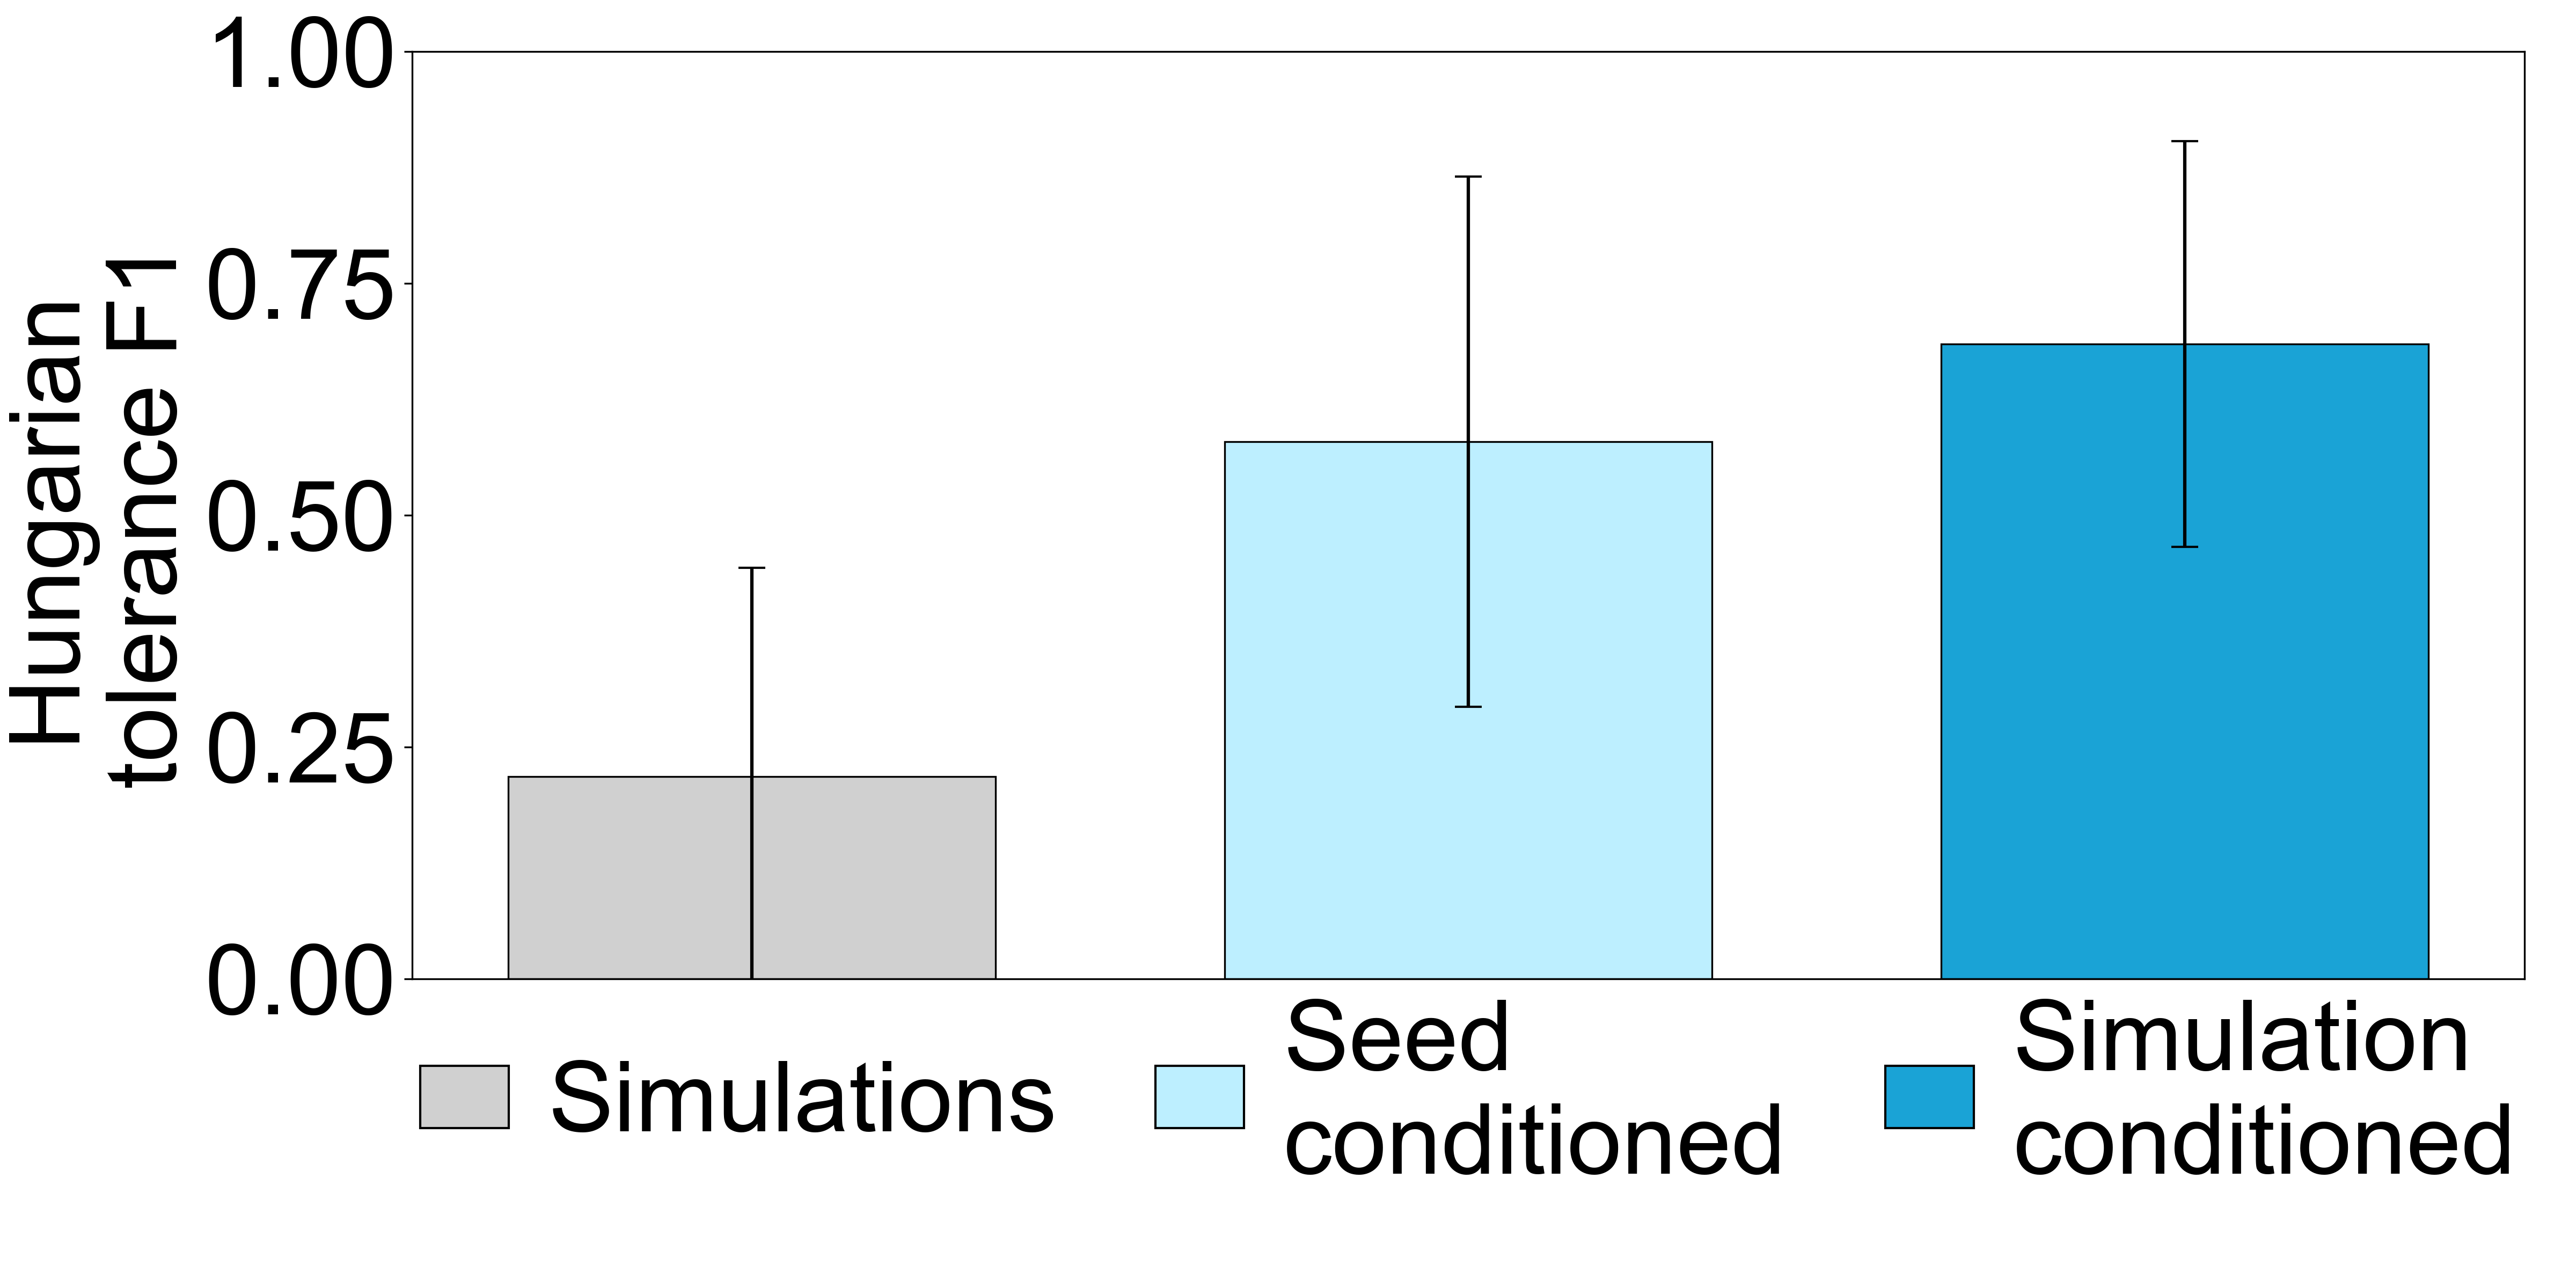

In [7]:
from matplotlib import font_manager as fm
from matplotlib.patches import Patch
from utils import config

if Path(config.FPATH).is_file():
    fm.fontManager.addfont(str(config.FPATH))
    PLOT_FONT_FAMILY = fm.FontProperties(fname=str(config.FPATH)).get_name()
else:
    PLOT_FONT_FAMILY = 'Arial'
PLOT_LABEL_FONTSIZE = 44
PLOT_TITLE_FONTSIZE = 44
PLOT_TICK_FONTSIZE = 44
PLOT_LEGEND_FONTSIZE = 44

colors = {
    METHODS[0]: '#D0D0D0',
    METHODS[1]: '#BDEFFF',
    METHODS[2]: '#1AA3D6',
}

fig, ax = plt.subplots(figsize=(16, 8))
x = np.arange(len(METHODS))
means = [float(summary.loc[summary['method'] == method, 'mean'].iloc[0]) for method in METHODS]
standard_deviations = [float(summary.loc[summary['method'] == method, 'std'].iloc[0]) for method in METHODS]
ax.bar(x, means, yerr=standard_deviations, capsize=6, width=0.68,
       color=[colors[method] for method in METHODS], edgecolor='black', linewidth=0.8)
ax.set_xticks([])
# ax.set_title('Mean ± SD across 132 experimental patterns',
            #  fontsize=PLOT_TITLE_FONTSIZE, fontfamily=PLOT_FONT_FAMILY)
ax.set_ylabel('Hungarian\ntolerance F1', fontsize=PLOT_LABEL_FONTSIZE,
              fontfamily=PLOT_FONT_FAMILY)
ax.set_ylim(0, 1)
ax.tick_params(axis='both', labelsize=PLOT_TICK_FONTSIZE)
for label in (*ax.get_xticklabels(), *ax.get_yticklabels()):
    label.set_fontfamily(PLOT_FONT_FAMILY)
legend_labels = ['Simulations', 'Seed\nconditioned', 'Simulation\nconditioned']
legend_handles = [
    Patch(facecolor=colors[method], edgecolor='black', label=label)
    for method, label in zip(METHODS, legend_labels)
]
fig.subplots_adjust(bottom=0.24, left=0.16, right=0.98, top=0.96)
legend_center = ax.get_position().x0 + ax.get_position().width / 2
fig.legend(
    handles=legend_handles, loc='lower center', ncol=len(METHODS),
    bbox_to_anchor=(legend_center, 0.005), frameon=False,
    prop={'family': PLOT_FONT_FAMILY, 'size': PLOT_LEGEND_FONTSIZE},
    handlelength=0.9, handleheight=0.6, handletextpad=0.4, columnspacing=1.0,
)
plot_path = OUTPUT_DIR / 'conditioning_source_radius4_mean_sd.png'
fig.savefig(plot_path, dpi=300)
fig.savefig(OUTPUT_DIR / 'conditioning_source_radius4_mean_sd.pdf')
display(Image(filename=str(plot_path)))
plt.close(fig)


In [ ]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 18D — inverse-decoder conditioning comparison
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'information_encoding_decoding' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'SuppFig18D_conditioning_inverse_F1.pdf')


Saved tables, figures, and provenance to: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/conditioning_source_comparison_real_test_4gpu_lr5e4


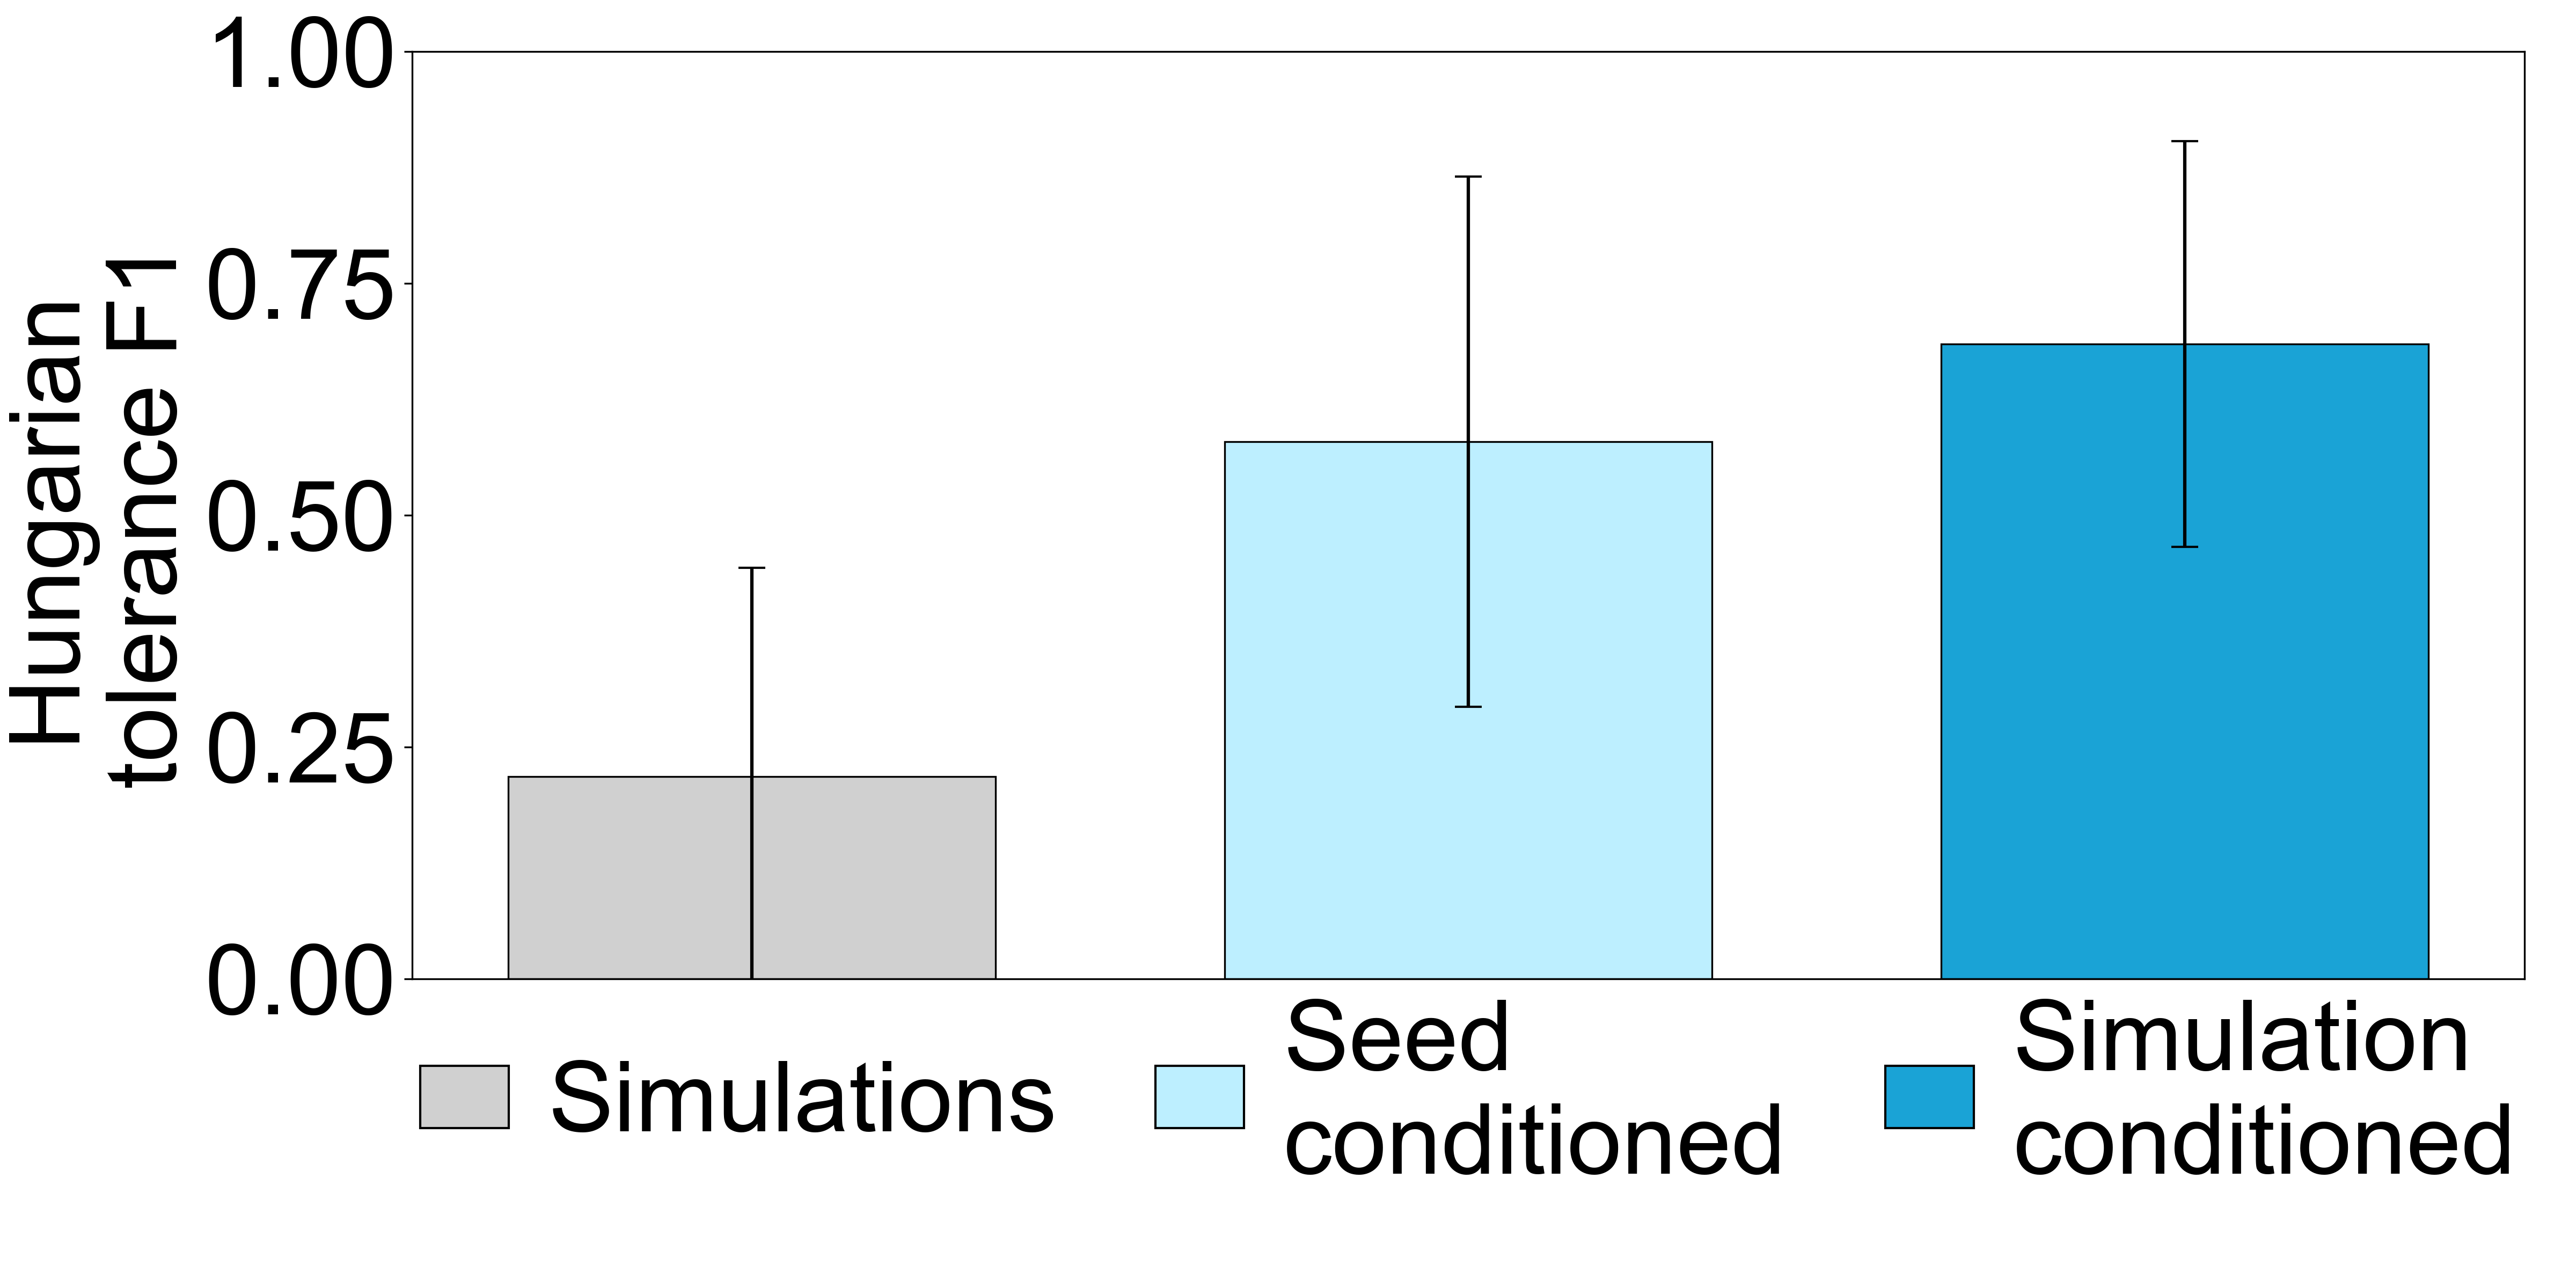

In [8]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
settings = {
    'analysis': 'raw vs seed-conditioned vs simulation-conditioned inverse decoding',
    'device': str(device),
    'number_test_images': len(targets),
    'test_set': test_inventory,
    'prediction_threshold': PREDICTION_THRESHOLD,
    'matching_algorithm': 'hungarian',
    'matching_tolerance_pixels': MATCHING_TOLERANCE,
    'bar_error_bars': 'standard deviation across per-image tolerance F1 values',
    'paired_difference_uncertainty': '95% paired bootstrap CI, 10,000 resamples, seed 42',
    'raw_simulation': {
        'prediction_directory': str(RAW_SIMULATION_PREDICTIONS.resolve()),
        'checkpoint_provenance': str(RAW_SIMULATION_CHECKPOINT_PROVENANCE.resolve()),
        'checkpoint_sha256': sha256(RAW_SIMULATION_CHECKPOINT_PROVENANCE),
    },
    'seed_conditioned': {
        'using_corrected_run': True,
        **seed_provenance,
    },
    'simulation_conditioned': simulation_provenance,
}
with (_figure_source_path(OUTPUT_DIR / 'evaluation_settings.json')).open('w') as handle:
    json.dump(settings, handle, indent=2)

print(f'Saved tables, figures, and provenance to: {OUTPUT_DIR.resolve()}')
display(Image(filename=str(OUTPUT_DIR / 'conditioning_source_radius4_mean_sd.png')))
